# CODA-19 – Segmentierung und Klassifikation wissenschaftlicher Abstracts mit Qwen3.5-4B

**Datensatz:** CODA-19 (Huang et al., 2020) – Abstracts von COVID-19- und Coronavirus-Papern, von Menschen annotiert. Jedes Abstract ist in Segmente (Teilsätze) zerlegt, jedes Segment trägt eine von fünf Forschungsaspekten: `background`, `purpose`, `method`, `finding`, `other`.

**Aufgabe:** Das Modell bekommt das **komplette Abstract als Fließtext** und muss es **selbst segmentieren** und jedes Segment labeln. Ausgabe als JSON mit `segment_text`, `label`, `decision_reference` (Verweis auf die Codebuch-Regel) und `id`.

**Ansatz:** QLoRA-Fine-Tuning (4-Bit NF4) von `Qwen/Qwen3.5-4B`, LoRA r=96 / alpha=192 auf allen Attention- und MLP-Projektionen. Prompt maskiert; die Werte von `segment_text` und `label` werden im Loss 2-fach gewichtet.

**Bewertung:** Jedes Gold-Segment wird über die Zeichenüberlappung dem passenden vorhergesagten Segment zugeordnet. Treffer = gleiches Label. **Micro** = Treffer / alle Gold-Segmente; **Mittel pro Abstract** = Durchschnitt der Trefferquoten je Abstract.

**Ergebnis auf 400 Test-Abstracts (keine Überschneidung mit dem Training):**

| | Micro über Segmente | Mittel pro Abstract | JSON-Fehler |
|---|---|---|---|
| Basismodell, Zero-Shot | 76,14 % | 75,26 % | 5 |
| **Fine-Tuned (Checkpoint 1375)** | **88,18 %** | **87,32 %** | **0** |

**Vergleich auf DEV-181** (181 Abstracts mit höchstens 25 Segmenten; hier wurden die Prompt-Varianten des Basismodells verglichen):

| | Micro über Segmente |
|---|---|
| Basismodell, Zero-Shot ohne Abgrenzungsregeln | 76,65 % |
| Basismodell, Abgrenzungsregeln nach dem Abstract + 3 konstruierte Kontrast-Few-Shots | 78,09 % |
| Basismodell, Abgrenzungsregeln + 4 Few-Shots mit `decision_reference` | 78,90 % |
| **Fine-Tuned (Checkpoint 1375)** | **86,62 %** |

Training auf einer gemieteten RTX 3090 (vast.ai).

## 1. Setup

In [ ]:
# Nur auf frischen vast.ai-Instanzen nötig – installiert in die Python-Umgebung des Kernels
import sys
!{sys.executable} -m pip install -r requirements.txt

In [ ]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import json, re, random, subprocess
import numpy as np
import torch
import torch.nn as nn
import transformers, datasets, peft, trl
import bitsandbytes as bnb
import pandas as pd
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig,
                          Trainer, TrainingArguments, TrainerCallback, default_data_collator)
from peft import LoraConfig, prepare_model_for_kbit_training, get_peft_model, PeftModel

print("transformers:", transformers.__version__)
print("datasets:", datasets.__version__)
print("peft:", peft.__version__)
print("bitsandbytes:", bnb.__version__)
print("trl:", trl.__version__)
print("pandas:", pd.__version__)
print("GPU:", torch.cuda.get_device_name(0))

transformers: 5.12.1
datasets: 5.0.0
peft: 0.19.1
bitsandbytes: 0.49.2
trl: 1.6.0
pandas: 3.0.3
GPU: NVIDIA GeForce RTX 3090


## 2. Konfiguration

In [ ]:
MODEL_ID   = "Qwen/Qwen3.5-4B"
OUTPUT_DIR = "/workspace/LORA_AbstractDecomposer_Qwen3.5_4b"

TRAIN_PATH = "/workspace/coda19_train_6000_final_sft.jsonl"   # 6.000 Abstracts, höchstens 30 Segmente je Abstract
EVAL_PATH  = "/workspace/coda19_test_400_final_sft.jsonl"     # 400 Test-Abstracts, höchstens 30 Segmente, keine paper_id-Überschneidung mit Train
DEV_PATH   = "/workspace/coda19_dev_200_max25.jsonl"      # 181 Dev-Abstracts (200, auf höchstens 25 Segmente begrenzt), nur für die Auswertung


## 3. Daten laden und formatieren

Jedes Beispiel ist im Chat-Format gespeichert (`system`, `user`, `assistant`). Für das Training werden System-Prompt und User-Nachricht roh aneinandergehängt – ohne Chat-Template, exakt so wie später in der Auswertung. Die User-Nachricht enthält das Abstract und kurze Abgrenzungsregeln zwischen benachbarten Aspekten (`BOUNDARY RULES`).

**Aufteilung:** Train 6.000, Dev 181, Test 400 Abstracts, ohne `paper_id`-Überschneidung. Abstracts mit sehr vielen Segmenten wurden begrenzt (Train und Test höchstens 30, Dev höchstens 25), weil sehr lange Abstracts zu viel Speicher brauchten.

In [ ]:
train_dataset = load_dataset("json", data_files=TRAIN_PATH, split="train")
eval_dataset  = load_dataset("json", data_files=EVAL_PATH,  split="train")

print(train_dataset)
print(eval_dataset)

Dataset({
    features: ['paper_id', 'messages'],
    num_rows: 6000
})
Dataset({
    features: ['paper_id', 'messages'],
    num_rows: 400
})


In [ ]:
def format_example(example):
    msgs = example["messages"]
    system = msgs[0]["content"]
    user   = msgs[1]["content"]
    target = msgs[2]["content"]
    return {
        "input_text":  system + "\n\n" + user,
        "output_text": target
    }

train_dataset = train_dataset.map(format_example)
eval_dataset  = eval_dataset.map(format_example)

print("=== TRAIN SAMPLE ===")
print("INPUT:\n", train_dataset[0]["input_text"][:3500])
print("\nOUTPUT:\n", train_dataset[0]["output_text"][:500])
print("\ntrain items:", len(train_dataset))
print("eval items:", len(eval_dataset))

=== TRAIN SAMPLE ===
INPUT:
 You are a precise annotator for scientific abstracts. You receive a COMPLETE abstract as running text. Your task has two steps:

1. SEGMENT: Split the abstract into consecutive segments (clauses). A segment is the smallest unit that carries its own rhetorical function. A sentence may split into several segments when its function changes. The segments must cover the original text without gaps or overlaps.

2. LABEL: Assign each segment exactly one of five research aspects:
- background: known context, motivation, problem, prior state of research.
- purpose: the concrete aim, research question, or hypothesis of THIS work.
- method: how the work was carried out (procedure, materials, data, analysis).
- finding: results, outcomes, conclusions, implications of THIS work.
- other: anything with no research function (boilerplate, copyright, metadata, broken fragments).

Classify by the rhetorical FUNCTION of the segment, not by its subject matter.

Output: Return 

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

## 4. Tokenisierung: Label-Maske und gewichteter Loss

- **Label-Maske:** Prompt-Tokens erhalten das Label `-100` und zählen nicht zum Loss.
- **Loss-Gewichtung:** Über `offset_mapping` werden die Zeichenpositionen der Ausgabe-Tokens bestimmt. Tokens innerhalb der **Werte** von `segment_text` und `label` bekommen Gewicht **2,0**, alle übrigen Ausgabe-Tokens (JSON-Gerüst, `decision_reference`, `id`) 1,0. Damit zählen Segmentgrenzen und Labels doppelt – das ist, was bewertet wird.
- Kein Padding in der Tokenisierung; bei Batchgröße 1 ist keines nötig. Eine frühere Fassung hat alle Sequenzen vorab auf volle Länge aufgefüllt; ohne dieses Padding sank die geschätzte Trainingszeit von etwa 55 auf etwa 22 Stunden.

In [ ]:
import re

MAX_LENGTH = 4000
MAX_OUTPUT_TOKENS = 2000
MAX_INPUT_TOKENS = MAX_LENGTH - MAX_OUTPUT_TOKENS


def tokenize_example(example):
    input_text  = example["input_text"]
    output_text = example["output_text"] + tokenizer.eos_token
    tokenized_input = tokenizer(input_text, truncation=True, max_length=MAX_INPUT_TOKENS,
                                padding=False, add_special_tokens=False)
    tokenized_output = tokenizer(output_text, truncation=True, max_length=MAX_OUTPUT_TOKENS,
                                 padding=False, add_special_tokens=False,
                                 return_offsets_mapping=True)

    input_ids  = tokenized_input["input_ids"]
    output_ids = tokenized_output["input_ids"]

    spans = [(m.start(1), m.end(1))
             for m in re.finditer(r'"(?:segment_text|label)":\s*("[^"]*")', output_text)]
    out_weights = [2.0 if a != b and any(a < e and b > s for s, e in spans) else 1.0
                   for (a, b) in tokenized_output["offset_mapping"]]

    full_ids     = (input_ids + output_ids)[:MAX_LENGTH]
    labels       = ([-100]*len(input_ids) + output_ids)[:MAX_LENGTH]
    loss_weights = ([0.0]*len(input_ids) + out_weights)[:MAX_LENGTH]  # spiegelt labels
    attention_mask = [1]*len(full_ids)


    return {
        "input_ids": full_ids,
        "attention_mask": attention_mask,
        "labels": labels,
        "loss_weights": loss_weights,
    }


tokenized_train2 = train_dataset.map(tokenize_example)
tokenized_eval = eval_dataset.map(tokenize_example)

tokenized_train2 = tokenized_train2.remove_columns(train_dataset.column_names)
tokenized_eval = tokenized_eval.remove_columns(eval_dataset.column_names)

print(train_dataset.column_names)
print(tokenized_train2.column_names)

['paper_id', 'messages', 'input_text', 'output_text']
['input_ids', 'attention_mask', 'labels', 'loss_weights']


Längenprüfung: Nichts wird abgeschnitten.

In [ ]:
def token_len(text):
    return len(tokenizer(text, add_special_tokens=False)["input_ids"])

input_lens = [token_len(x["input_text"]) for x in train_dataset]
output_lens = [token_len(x["output_text"] + tokenizer.eos_token) for x in train_dataset]

print("max input:", max(input_lens))
print("max output:", max(output_lens))
print("truncated inputs:", sum(x > MAX_INPUT_TOKENS for x in input_lens))
print("truncated outputs:", sum(x > MAX_OUTPUT_TOKENS for x in output_lens))

max input: 1922
max output: 1928
truncated inputs: 0
truncated outputs: 0


Kontrolle: Welche Tokens werden gelernt? (nur die JSON-Ausgabe)

In [ ]:
import numpy as np
ex = tokenized_train2[0]
lab = np.array(ex["labels"]); ids = np.array(ex["input_ids"])
print("-100-Anteil:", round((lab==-100).mean(),3), "| gelabelt:", (lab!=-100).sum())
print(tokenizer.decode(ids[lab!=-100]))

-100-Anteil: 0.584 | gelabelt: 781
{"segments": [{"segment_text": "Clough , E.R. and Dean , H.J. , 1988 .", "label": "other", "decision_reference": "other.definition", "id": 1}, {"segment_text": "Isolation and characterization of lymphocytes from bovine intestinal epithelium and lamina propria .", "label": "background", "decision_reference": "background.definition", "id": 2}, {"segment_text": "Vet .", "label": "other", "decision_reference": "other.definition", "id": 3}, {"segment_text": "Immunol .", "label": "other", "decision_reference": "other.definition", "id": 4}, {"segment_text": "Immunopathol. , The lymphocyte populations of the bovine gut lamina proprial ( LP ) and epithelial tissues were isolated and characterized with respect to cells bearing surface and cytoplasmic immunoglobulin ( Ig ) .", "label": "background", "decision_reference": "background.definition", "id": 5}, {"segment_text": "Functional characteristics of cells from the two tissues ,", "label": "method", "decision_

Kontrolle: Wo sitzt das Gewicht 2,0? (2,0-Tokens in «»)

In [ ]:
# Smoke-Test: sitzt Faktor 2.0 auf segment_text- und label-Werten?
ex   = tokenized_train2[0]
ids  = ex["input_ids"]; labs = ex["labels"]; w = ex["loss_weights"]
WMAX = max(w)                       # = 2.0; robust, falls Basis 1.0 / Pad 0.0
print("max loss_weight =", WMAX, "\n")

# (A) Output-Teil als Fließtext, 2x-Tokens in «»  -> Augenschein
print("Output mit «2.0x»-Markierung:")
print("".join(("«"+tokenizer.decode([ids[i]])+"»") if (labs[i] != -100 and w[i] == WMAX)
               else (tokenizer.decode([ids[i]]) if labs[i] != -100 else "")
               for i in range(len(ids))), "\n")

# (B) zusammenhängende 2x-Läufe einzeln, mit 2 Tokens Vorlauf als Kontext
print("2x-Spannen (Kontext -> [HOCHGEWICHTET]):")
i = 0
while i < len(ids):
    if w[i] == WMAX and labs[i] != -100:
        j = i
        while j < len(ids) and w[j] == WMAX and labs[j] != -100:
            j += 1
        ctx  = tokenizer.decode([ids[k] for k in range(max(0, i-3), i)])
        span = tokenizer.decode([ids[k] for k in range(i, j)])
        print(f"  …{ctx!r} -> [{span!r}]")
        i = j
    else:
        i += 1

max loss_weight = 2.0 

Output mit «2.0x»-Markierung:
{"segments": [{"segment_text":« "»«Cl»«ough»« ,»« E»«.R»«.»« and»« Dean»« ,»« H»«.J»«.»« ,»« »«1»«9»«8»«8»« .»«",» "label":« "»«other»«",» "decision_reference": "other.definition", "id": 1}, {"segment_text":« "»«Is»«olation»« and»« characterization»« of»« lymph»«ocytes»« from»« bo»«vine»« intestinal»« epith»«el»«ium»« and»« lam»«ina»« propria»« .»«",» "label":« "»«background»«",» "decision_reference": "background.definition", "id": 2}, {"segment_text":« "»«V»«et»« .»«",» "label":« "»«other»«",» "decision_reference": "other.definition", "id": 3}, {"segment_text":« "»«Im»«mun»«ol»« .»«",» "label":« "»«other»«",» "decision_reference": "other.definition", "id": 4}, {"segment_text":« "»«Im»«mun»«opath»«ol»«.»« ,»« The»« lymph»«ocyte»« populations»« of»« the»« bo»«vine»« gut»« lam»«ina»« prop»«rial»« (»« LP»« )»« and»« epith»«elial»« tissues»« were»« isolated»« and»« characterized»« with»« respect»« to»« cells»« bearing»« surface»« and»« 

## 5. QLoRA-Konfiguration

In [ ]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True
)

lora_config = LoraConfig(
    r=96,
    lora_alpha=192,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

## 6. Modell laden und LoRA anwenden

In [ ]:
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
    dtype=torch.bfloat16,
)
model = prepare_model_for_kbit_training(model)
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

trainable params: 127,401,984 || all params: 4,333,153,280 || trainable%: 2.9402


## 7. Training

- Batchgröße 1 × 8 Gradient Accumulation, 3 Epochen geplant → 750 Schritte pro Epoche.
- Eval-Loss wird regelmäßig gemessen; am Ende wird der Checkpoint mit dem niedrigsten Eval-Loss geladen (`load_best_model_at_end`).
- Eigene `compute_loss`: Cross-Entropy pro Token × Gewicht, geteilt durch die Summe der Gewichte, plus korrekte Normierung über Gradient Accumulation.

In [ ]:
from transformers import TrainerCallback
import subprocess

class VRAMCallback(TrainerCallback):
    def on_save(self, args, state, control, **kwargs):
        result = subprocess.run(
            ["nvidia-smi", "--query-gpu=memory.used,memory.total", "--format=csv,noheader,nounits"],
            capture_output=True, text=True
        )
        used, total = result.stdout.strip().split(", ")
        print(f"[Step {state.global_step}] VRAM: {used} MB / {total} MB")

In [ ]:
from transformers import Trainer, default_data_collator
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,
    num_train_epochs=3,
    logging_steps=10,
    save_strategy="steps",
    save_steps=125,
    save_total_limit=15,

    save_only_model=True,
    remove_unused_columns=False,
    

    eval_strategy="steps",
    eval_steps=125,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    per_device_eval_batch_size=1,
    eval_accumulation_steps=1,
    
    bf16=True,

    learning_rate=5e-5,
    weight_decay=0.004,
    lr_scheduler_type="cosine",
    warmup_steps=120,
    optim="paged_adamw_8bit",
    
    report_to="none"
)

In [ ]:
import torch.nn as nn

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        weights = inputs.pop("loss_weights")
        labels  = inputs.pop("labels")
        logits  = model(**inputs).logits

        # Shift: Token t sagt Token t+1 voraus
        logits  = logits[:, :-1, :]
        labels  = labels[:, 1:]
        weights = weights[:, 1:]

        V = logits.size(-1)
        ce = nn.CrossEntropyLoss(reduction="none", ignore_index=-100)
        # reshape statt transpose: kein Kopieren des B×T×V-Tensors -> spart Speicher + ~25-30% Zeit
        per_tok = ce(logits.reshape(-1, V), labels.reshape(-1))      # (B*T,)

        w = (weights * (labels != -100)).reshape(-1)                  # (B*T,)
        loss = (per_tok * w).sum() / w.sum().clamp(min=1)             # gewichteter Mittel pro Token

        # Korrekte Normierung über Gradient-Accumulation:
        # Neuere HF-Trainer summieren die per-Step-Losses und teilen NICHT mehr selbst durch
        # gradient_accumulation_steps. Wenn num_items_in_batch übergeben wird, sind wir in
        # diesem Modus -> wir müssen selbst teilen, sonst sind Anzeige UND Gradienten ×grad_accum.
        if num_items_in_batch is not None:
            loss = loss / self.args.gradient_accumulation_steps

        return (loss, logits) if return_outputs else loss

In [ ]:
trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train2,
    eval_dataset=tokenized_eval,
    data_collator=default_data_collator,
    callbacks=[VRAMCallback()],
)

model.train()
model.config.use_cache = False
trainer.train()
# Der Lauf wurde zweimal unterbrochen (Abbrüche der Notebook-Sitzung, einmal volle Festplatte)
# und aus dem letzten Checkpoint fortgesetzt (im Log beginnt das Warmup bei Schritt 630 und 760 neu), zuletzt mit:
# trainer.train(resume_from_checkpoint=f"{OUTPUT_DIR}/checkpoint-750")

Verlauf von Trainings- und Eval-Loss laut `trainer_state.json` von Checkpoint 1375; die Datei endet deshalb bei Schritt 1375. Das Training lief bis Schritt 1867 von 2250 geplanten (2,49 von 3 Epochen) und wurde dann abgebrochen. Ausgewählt wurde Checkpoint 1375 mit dem niedrigsten Eval-Loss; die späteren Checkpoints lagen bei 0,00118 bis 0,00119.

In [ ]:
import json
st = json.load(open("training_logs/trainer_state.json"))
print("bester Checkpoint:", st["best_model_checkpoint"].split("/")[-1], "| Eval-Loss", round(st["best_metric"], 6))
print(f"{'Schritt':>7} {'Train-Loss':>11} {'Eval-Loss':>10}")
train = {e["step"]: e["loss"] for e in st["log_history"] if "loss" in e}
for e in st["log_history"]:
    if "eval_loss" in e:
        s = e["step"]
        print(f"{s:7d} {train.get(s - 5, train.get(s, float('nan'))):11.4f} {e['eval_loss']:10.5f}")


bester Checkpoint: checkpoint-1375 | Eval-Loss 0.001145
Schritt  Train-Loss  Eval-Loss
    125      0.0147    0.00198
    250      0.0113    0.00150
    375      0.0105    0.00146
    500      0.0085    0.00138
    625      0.0103    0.00124
    750      0.0106    0.00133
    875      0.0081    0.00135
   1000      0.0085    0.00129
   1125      0.0074    0.00120
   1250      0.0077    0.00124
   1375      0.0087    0.00115


**Warum der Loss so klein ist und wenig aussagt:** Der größte Teil des Targets ist vorhersagbar – `segment_text` ist eine wörtliche Kopie aus dem Abstract, JSON-Gerüst, Feldnamen und `decision_reference`-Bausteine wiederholen sich in jedem Item. Diese Tokens lernt das Modell sofort, ihr Loss liegt danach praktisch bei null. Echte Entscheidungen stecken nur in wenigen Tokens pro Segment (Label und Segmentgrenze). Weil der Loss über alle Tokens gemittelt wird, bewegt er sich bei Label-Änderungen kaum. Der Eval-Loss diente deshalb nur zur Beobachtung und Checkpoint-Wahl; maßgeblich ist die Genauigkeit in Abschnitt 9 und 11.

## 8. Checkpoint 1375 laden

In [ ]:
BASE_MODEL = "Qwen/Qwen3.5-4B"
BEST_CHECKPOINT = "/workspace/LORA_AbstractDecomposer_Qwen3.5_4b/checkpoint-1375/"

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    quantization_config=bnb_config,
    device_map="auto",
    dtype=torch.bfloat16,
)

model = PeftModel.from_pretrained(base_model, BEST_CHECKPOINT)
model.eval()

In [ ]:
import torch
for n,p in model.named_parameters():
    if "lora_B" in n and "layers.0." in n:
        print(n, float(p.abs().sum())); break
# ~0.0  -> NICHTS geladen (zero-init), Adapter wirkungslos
# >0    -> geladen, alles gut

base_model.model.model.layers.0.mlp.gate_proj.lora_B.default.weight 895.4556274414062


## 9. Auswertung auf TEST-400

Greedy-Generierung (max. 2000 neue Tokens), JSON-Parsing (mit Bergung vollständiger Segmente bei abgeschnittenem JSON), Zuordnung über Zeichenüberlappung, Confusion-Matrix. Für DEV-181 wird die auskommentierte Zeile in `EVAL_SETS` aktiviert.

In [ ]:
import json, re, torch
from collections import Counter
from pathlib import Path

ASPECTS = ["background", "purpose", "method", "finding", "other"]
MAX_NEW_TOKENS = 2000
MODEL_CTX = getattr(model.config, "max_position_embeddings", 32768)

def read_jsonl(p):
    return [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()]

# System-Prompt aus den TRAININGSDATEN (separate sysprompt-Datei ist veraltet)
SYSTEM_PROMPT = read_jsonl("/workspace/coda19_test_400_final_sft.jsonl")[0]["messages"][0]["content"]
RAG_OBJ = read_jsonl("/workspace/coda19_rag_doc_boundary_only.jsonl")[0]
RAG_GUID = RAG_OBJ.get("guidance", RAG_OBJ)
RAG_TEXT = json.dumps({"boundary_rules": RAG_GUID["boundary_rules"]}, ensure_ascii=False, indent=2) \
           if "boundary_rules" in RAG_GUID else json.dumps(RAG_GUID, ensure_ascii=False, indent=2)

EVAL_SETS = [
#    ("DEV-181",  "/workspace/coda19_dev_200_max25.jsonl"),
    ("TEST-400", "/workspace/coda19_test_400_final_sft.jsonl"),
]

def load_eval(path):
    out = []
    for r in read_jsonl(path):
        if "abstract_text" in r and "gold_segments" in r:
            out.append({"paper_id": r.get("paper_id"),
                        "abstract_text": r["abstract_text"],
                        "gold_segments": r["gold_segments"],
                        "ready_user": None})
        else:
            ready_user = r["messages"][1]["content"]
            abs_ = ready_user.split("ABSTRACT:\n", 1)[1]
            for cut in ["\n\nBOUNDARY", "\n\nReturn the JSON"]:
                if cut in abs_: abs_ = abs_.split(cut, 1)[0]; break
            tgt = json.loads(r["messages"][2]["content"])
            gold = [{"segment_text": s["segment_text"], "label": s["label"]} for s in tgt["segments"]]
            out.append({"paper_id": r.get("paper_id"),
                        "abstract_text": abs_.strip(),
                        "gold_segments": gold,
                        "ready_user": ready_user})
    return out

def build_prompt(item):
    if item["ready_user"] is not None:
        user = item["ready_user"]
    else:
        user = ("ABSTRACT:\n" + item["abstract_text"]
                + "\n\nBOUNDARY RULES (apply when two aspects are close):\n" + RAG_TEXT
                + "\n\nReturn the JSON object now.")
    return SYSTEM_PROMPT + "\n\n" + user          # ROH, exakt wie im Training

def strip_think(t):
    if "</think>" in t: t = t.split("</think>", 1)[1]
    return t.replace("<think>", "").strip()

def parse_pred(text):
    text = strip_think(text)
    # Versuch 1: sauberes JSON
    try:
        m = re.search(r"\{.*\}", text, re.S)
        if m:
            segs = json.loads(m.group(0), strict=False).get("segments", [])
            out = [(str(s.get("segment_text","")).strip(), str(s.get("label","")).strip().lower())
                   for s in segs if str(s.get("segment_text","")).strip() and str(s.get("label","")).strip().lower() in ASPECTS]
            if out: return out, True
    except Exception:
        pass
    # Versuch 2: abgeschnittenes JSON — vollständige Segment-Objekte einzeln bergen
    out = []
    for sm in re.finditer(r'\{[^{}]*?"segment_text"\s*:\s*"((?:[^"\\]|\\.)*)"[^{}]*?"label"\s*:\s*"(\w+)"[^{}]*?\}', text, re.S):
        st = sm.group(1).strip(); lb = sm.group(2).strip().lower()
        if st and lb in ASPECTS:
            out.append((st, lb))
    return (out, bool(out))

def char_spans(abstract, frags):
    low = abstract.lower(); spans = []; cursor = 0
    for frag in frags:
        f = frag.lower().strip()
        idx = low.find(f[:40], cursor) if len(f) >= 1 else -1
        if idx == -1 and len(f) >= 20: idx = low.find(f[:20], cursor)
        if idx == -1: idx = low.find(f[:40]) if len(f) >= 1 else -1
        if idx == -1: start, end = cursor, min(len(abstract), cursor + max(1, len(f)))
        else: start, end = idx, idx + len(frag)
        spans.append((start, end)); cursor = max(cursor, start)
    return spans

def overlap(a, b): return max(0, min(a[1], b[1]) - max(a[0], b[0]))

def align_score(abstract, gold_segs, pred):
    gold_sp = char_spans(abstract, [g["segment_text"] for g in gold_segs])
    pred_sp = char_spans(abstract, [p[0] for p in pred]) if pred else []
    hits = 0; pairs = []
    for gs, g in zip(gold_sp, gold_segs):
        best_j, best_ov = -1, 0
        for pj, ps in enumerate(pred_sp):
            ov = overlap(gs, ps)
            if ov > best_ov: best_ov, best_j = ov, pj
        pl = pred[best_j][1] if best_j >= 0 else None
        ok = (pl == g["label"]); hits += int(ok)
        pairs.append({"gold": g["label"], "pred": pl, "ok": ok})
    return hits, len(gold_segs), pairs

model.eval()
for SET_NAME, SET_PATH in EVAL_SETS:
    eval_items = load_eval(SET_PATH)
    prompt_lens = [len(tokenizer(build_prompt(it), add_special_tokens=False)["input_ids"]) for it in eval_items]
    over = [i for i, L in enumerate(prompt_lens) if L + MAX_NEW_TOKENS > MODEL_CTX]
    if over: raise RuntimeError(f"{SET_NAME} TRUNCATION: idx={over[0]} ({prompt_lens[over[0]]} tok)")
    print(f"=== {SET_NAME} ({len(eval_items)}) | max prompt {max(prompt_lens)} +{MAX_NEW_TOKENS} = {max(prompt_lens)+MAX_NEW_TOKENS} | ctx {MODEL_CTX} OK ===")

    sp = build_prompt(eval_items[0])
    e = tokenizer(sp, return_tensors="pt", add_special_tokens=False).to(model.device)
    with torch.no_grad():
        o = model.generate(**e, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                           pad_token_id=tokenizer.eos_token_id, eos_token_id=tokenizer.eos_token_id)
    g0 = tokenizer.decode(o[0][e["input_ids"].shape[1]:], skip_special_tokens=True)
    p0, ok0 = parse_pred(g0)
    h0, n0, _ = align_score(eval_items[0]["abstract_text"], eval_items[0]["gold_segments"], p0)
    print(f"SMOKE item1: gold={n0} pred={len(p0)} hits={h0}/{n0} json_ok={ok0}")
    print("SMOKE gen (erste 200):", g0[:200], "\n")

    RESULTS_PATH = f"/workspace/coda19_tuned_cp1375_{SET_NAME}_raw.jsonl"
    iss = 0.0; sc = st = jf = 0
    matrix = {g: Counter() for g in ASPECTS}
    rf = open(RESULTS_PATH, "w", encoding="utf-8")
    for i, it in enumerate(eval_items):
        enc = tokenizer(build_prompt(it), return_tensors="pt", add_special_tokens=False).to(model.device)
        with torch.no_grad():
            out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                                 pad_token_id=tokenizer.eos_token_id, eos_token_id=tokenizer.eos_token_id)
        gen = tokenizer.decode(out[0][enc["input_ids"].shape[1]:], skip_special_tokens=True)
        pred, json_ok = parse_pred(gen)
        if not json_ok: jf += 1
        hits, n_gold, pairs = align_score(it["abstract_text"], it["gold_segments"], pred)
        iss += hits / n_gold; sc += hits; st += n_gold
        for pr in pairs: matrix[pr["gold"]][pr["pred"] if pr["pred"] in ASPECTS else "UNKNOWN"] += 1
        run = iss / (i+1) * 100
        rf.write(json.dumps({"i": i+1, "paper_id": it.get("paper_id"), "n_gold": n_gold, "n_pred": len(pred),
            "item_score": round(hits/n_gold,4), "hits": hits, "json_ok": json_ok,
            "running_item_acc": round(run,2), "pairs": pairs,
            "abstract_text": it["abstract_text"], "generated": gen}, ensure_ascii=False) + "\n")
        rf.flush()
        print(f"[{i+1:03d}/{len(eval_items)}] {hits}/{n_gold}={hits/n_gold:.2f} mean={run:.1f}%")
    rf.close()
    n = len(eval_items)
    print(f"\n--- {SET_NAME} --- mean item: {iss/n*100:.2f}% | micro seg: {sc/st*100:.2f}% ({sc}/{st}) | json_fail: {jf}")
    cols = ASPECTS + ["UNKNOWN"]
    print(f"{'':11}" + "".join(f"{c[:9]:>11}" for c in cols))
    for g in ASPECTS: print(f"{g:11}" + "".join(f"{matrix[g].get(c,0):11d}" for c in cols))
    print("->", RESULTS_PATH, "\n")

=== TEST-400 (400) | max prompt 1573 +2000 = 3573 | ctx 262144 OK ===
SMOKE item1: gold=3 pred=3 hits=3/3 json_ok=True
SMOKE gen (erste 200): {"segments": [{"segment_text": "Interpretation Seroprevalence of MERS-CoV antibodies was signifi cantly higher in camel-exposed individuals than in the general population .", "label": "finding", "deci 

--- TEST-400 --- mean item: 87.32% | micro seg: 88.18% (4978/5645) | json_fail: 0
             backgroun    purpose     method    finding      other    UNKNOWN
background        1699         44         30         59          6          0
purpose             27        282         17         16          0          0
method              66         19        637         64          0          0
finding            149         22        104       2222         11          0
other                8          0          0         25        138          0
-> /workspace/coda19_tuned_cp1375_TEST-400_raw.jsonl 



## 10. Vergleich: Basismodell ohne Fine-Tuning

Gleiche 400 Test-Abstracts, unverändertes `Qwen/Qwen3.5-4B` (4-Bit), Zero-Shot mit eigenem System-Prompt ohne Abgrenzungsregeln, Chat-Template mit ausgeschaltetem Thinking. Bewertung identisch. (Lief in einem separaten Notebook mit frisch geladenem Basismodell.)

In [ ]:
# === CODA-19 BASE-EVAL auf TEST-400 — NO RAG, offizieller no-RAG-Sysprompt, Rules verworfen ===
import json, re, torch
from collections import Counter
from pathlib import Path

ASPECTS = ["background", "purpose", "method", "finding", "other"]
MAX_NEW_TOKENS = 1500
MODEL_CTX = getattr(model.config, "max_position_embeddings", 32768)
TEST_FILE    = "/workspace/coda19_test_400_final_sft.jsonl"          # <-- exakten Namen pruefen
SYS_FILE     = "/workspace/coda19_sysprompt_norag_zeroshot.jsonl"
RESULTS_PATH = "/workspace/coda19_base_norag_zeroshot_TEST400_raw.jsonl"

def read_jsonl(p):
    return [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()]

# ---- offizieller no-RAG-System-Prompt aus deiner Datei (kein RAG, keine Boundary Rules) ----
bundle = read_jsonl(SYS_FILE)[0]
SYSTEM_PROMPT, VERSION = bundle["system_prompt"], bundle["version"]
print("System-Prompt-Version:", VERSION)

# ---- aus den SFT-messages NUR Abstract + Gold ziehen; dortigen Sysprompt + Boundary Rules verwerfen ----
def extract_item(row):
    user = next(m["content"] for m in row["messages"] if m["role"] == "user")
    asst = next(m["content"] for m in row["messages"] if m["role"] == "assistant")
    m = re.search(r"ABSTRACT:\s*(.*?)(?:\n\s*BOUNDARY RULES|\Z)", user, re.S)
    abstract = (m.group(1).strip() if m else user.strip())
    gold = json.loads(asst).get("segments", [])
    gold_segments = [{"segment_text": g["segment_text"], "label": str(g["label"]).lower()}
                     for g in gold if str(g.get("label", "")).lower() in ASPECTS]
    return {"paper_id": row.get("paper_id"), "abstract_text": abstract, "gold_segments": gold_segments}

eval_items = [extract_item(r) for r in read_jsonl(TEST_FILE)]

def build_prompt(item):
    user = "ABSTRACT:\n" + item["abstract_text"] + "\n\nReturn the JSON object now."
    messages = [{"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": user}]
    try:
        return tokenizer.apply_chat_template(messages, tokenize=False,
                                             add_generation_prompt=True, enable_thinking=False)
    except TypeError:
        return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

def strip_think(text):
    if "</think>" in text: text = text.split("</think>", 1)[1]
    return text.replace("<think>", "").strip()

def parse_pred(text):
    text = strip_think(text)
    try:
        m = re.search(r"\{.*\}", text, re.S)
        if m:
            segs = json.loads(m.group(0), strict=False).get("segments", [])
            out = []
            for s in segs:
                st = str(s.get("segment_text", "")).strip()
                lb = str(s.get("label", "")).strip().lower()
                if st and lb in ASPECTS:
                    out.append((st, lb))
            if out:
                return out, True
    except Exception:
        pass
    return [], False

def char_spans(abstract, frags):
    low = abstract.lower(); spans = []; cursor = 0
    for frag in frags:
        f = frag.lower().strip()
        idx = low.find(f[:40], cursor) if len(f) >= 1 else -1
        if idx == -1 and len(f) >= 20: idx = low.find(f[:20], cursor)
        if idx == -1: idx = low.find(f[:40]) if len(f) >= 1 else -1
        if idx == -1:
            start, end = cursor, min(len(abstract), cursor + max(1, len(f)))
        else:
            start, end = idx, idx + len(frag)
        spans.append((start, end)); cursor = max(cursor, start)
    return spans

def overlap(a, b): return max(0, min(a[1], b[1]) - max(a[0], b[0]))

def align_score(abstract, gold_segs, pred):
    gold_sp = char_spans(abstract, [g["segment_text"] for g in gold_segs])
    pred_sp = char_spans(abstract, [p[0] for p in pred]) if pred else []
    hits = 0; pairs = []
    for gs, g in zip(gold_sp, gold_segs):
        best_j, best_ov = -1, 0
        for pj, ps in enumerate(pred_sp):
            ov = overlap(gs, ps)
            if ov > best_ov: best_ov, best_j = ov, pj
        pred_label = pred[best_j][1] if best_j >= 0 else None
        ok = (pred_label == g["label"]); hits += int(ok)
        pairs.append({"gold": g["label"], "pred": pred_label, "ok": ok})
    return hits, len(gold_segs), pairs

model.eval()

# ---- TRUNCATION-PREFLIGHT ----
print("=== TRUNCATION-CHECK (CODA-19 BASE, NO RAG, TEST-400) ===")
prompt_lens = [len(tokenizer(build_prompt(it), add_special_tokens=False)["input_ids"]) for it in eval_items]
max_prompt = max(prompt_lens)
print(f"Items: {len(eval_items)} | max prompt tok: {max_prompt} | +{MAX_NEW_TOKENS} gen = {max_prompt+MAX_NEW_TOKENS} | ctx: {MODEL_CTX}")
over = [i for i, L in enumerate(prompt_lens) if L + MAX_NEW_TOKENS > MODEL_CTX]
if over:
    raise RuntimeError(f"TRUNCATION-GEFAHR: {len(over)} Items ueber Context. Erstes idx={over[0]}")
print("OK - kein Input truncated.\n")

# ---- SMOKE item 1 ----
print("="*100); print("SMOKE ITEM 1 — INPUT"); print("="*100)
sp = build_prompt(eval_items[0]); print(sp)
print("="*100); print("SMOKE ITEM 1 — OUTPUT (roh)"); print("="*100)
_e = tokenizer(sp, return_tensors="pt", add_special_tokens=False).to(model.device)
with torch.no_grad():
    _o = model.generate(**_e, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                        pad_token_id=tokenizer.eos_token_id, eos_token_id=tokenizer.eos_token_id)
_g = tokenizer.decode(_o[0][_e["input_ids"].shape[1]:], skip_special_tokens=True)
print(_g)
_p, _ok = parse_pred(_g)
_h, _n, _ = align_score(eval_items[0]["abstract_text"], eval_items[0]["gold_segments"], _p)
print(f"\n--> gold={_n} | pred={len(_p)} | hits={_h}/{_n}={_h/max(_n,1):.2f} | json_ok={_ok}")
print("="*100 + "\n")

# ---- VOLLER LAUF (Streaming) ----
item_score_sum = 0.0; seg_correct = seg_total = json_fail = 0
matrix = {g: Counter() for g in ASPECTS}
rf = open(RESULTS_PATH, "w", encoding="utf-8")
for i, it in enumerate(eval_items):
    enc = tokenizer(build_prompt(it), return_tensors="pt", add_special_tokens=False).to(model.device)
    with torch.no_grad():
        out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                             pad_token_id=tokenizer.eos_token_id, eos_token_id=tokenizer.eos_token_id)
    gen = tokenizer.decode(out[0][enc["input_ids"].shape[1]:], skip_special_tokens=True)
    pred, json_ok = parse_pred(gen)
    if not json_ok: json_fail += 1
    hits, n_gold, pairs = align_score(it["abstract_text"], it["gold_segments"], pred)
    item_score = hits / n_gold if n_gold else 0.0
    item_score_sum += item_score; seg_correct += hits; seg_total += n_gold
    for pr in pairs:
        matrix[pr["gold"]][pr["pred"] if pr["pred"] in ASPECTS else "UNKNOWN"] += 1
    run_acc = item_score_sum / (i+1) * 100
    rf.write(json.dumps({"i": i+1, "paper_id": it["paper_id"], "n_gold": n_gold, "n_pred": len(pred),
                         "item_score": round(item_score, 4), "hits": hits, "json_ok": json_ok,
                         "running_item_acc": round(run_acc, 2), "pairs": pairs,
                         "abstract_text": it["abstract_text"], "generated": gen}, ensure_ascii=False) + "\n")
    rf.flush()
    print(f"[{i+1:03d}/{len(eval_items)}] item={hits}/{n_gold}={item_score:.2f} (pred={len(pred)}) mean={run_acc:.1f}%")
rf.close()

n = len(eval_items)
print("\n" + "="*60)
print(f"CODA-19 BASE NO-RAG zero-shot | TEST-400 | sys={VERSION} | Items: {n}")
print(f"Mean item-score: {item_score_sum/n*100:.2f}%")
print(f"Micro segment-acc: {seg_correct/seg_total*100:.2f}%  ({seg_correct}/{seg_total})")
print(f"JSON-Fehler: {json_fail}")
cols = ASPECTS + ["UNKNOWN"]
print("\nConfusion (rows=gold, cols=pred):")
print(f"{'':11}" + "".join(f"{c[:9]:>11}" for c in cols))
for g in ASPECTS:
    print(f"{g:11}" + "".join(f"{matrix[g].get(c,0):11d}" for c in cols))
print("\nResults:", RESULTS_PATH)

System-Prompt-Version: coda19_sys_norag_zeroshot_v1
=== TRUNCATION-CHECK (CODA-19 BASE, NO RAG, TEST-400) ===
Items: 400 | max prompt tok: 1123 | +1500 gen = 2623 | ctx: 262144
OK - kein Input truncated.

...

CODA-19 BASE NO-RAG zero-shot | TEST-400 | sys=coda19_sys_norag_zeroshot_v1 | Items: 400
Mean item-score: 75.26%
Micro segment-acc: 76.14%  (4298/5645)
JSON-Fehler: 5

Confusion (rows=gold, cols=pred):
             backgroun    purpose     method    finding      other    UNKNOWN
background        1460        160         69         75         48         26
purpose             26        285         18          3          5          5
method              10        117        562         72          1         24
finding             62        116        269       1842        132         87
other                1          0          7          5        149          9

Results: /workspace/coda19_base_norag_zeroshot_TEST400_raw.jsonl


## 11. Ergebnisse im Detail

Geladen aus den gespeicherten Ergebnisdateien (eine Zeile pro Abstract, mit Roh-Ausgabe und Zuordnung jedes Gold-Segments).

Basismodell (Zero-Shot), TEST-400: 400 Abstracts, 5645 Gold-Segmente
  Micro 4298/5645 = 76.14 %  |  Mittel pro Abstract 75.26 %  |  JSON-Fehler 5
  Klasse          n Precision  Recall     F1
  background   1838     0.936   0.794  0.860
  purpose       342     0.420   0.833  0.559
  method        786     0.608   0.715  0.657
  finding      2508     0.922   0.734  0.818
  other         171     0.445   0.871  0.589

Fine-Tuned cp1375, TEST-400: 400 Abstracts, 5645 Gold-Segmente
  Micro 4978/5645 = 88.18 %  |  Mittel pro Abstract 87.32 %  |  JSON-Fehler 0
  Klasse          n Precision  Recall     F1
  background   1838     0.872   0.924  0.897
  purpose       342     0.768   0.825  0.795
  method        786     0.808   0.810  0.809
  finding      2508     0.931   0.886  0.908
  other         171     0.890   0.807  0.847

Fine-Tuned cp1375, DEV-181: 181 Abstracts, 2488 Gold-Segmente
  Micro 2155/2488 = 86.62 %  |  Mittel pro Abstract 85.27 %  |  JSON-Fehler 0
  Klasse          n Precision 

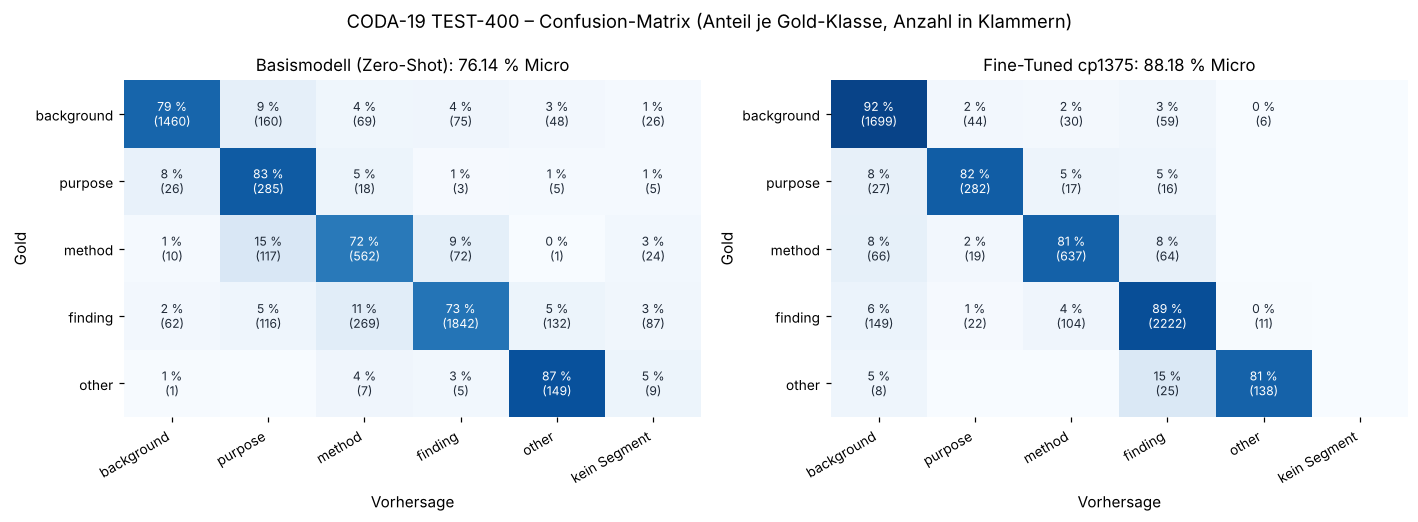

In [ ]:
import json
from collections import Counter
import matplotlib.pyplot as plt

ASPECTS = ["background", "purpose", "method", "finding", "other"]
RUNS = {
    "Basismodell (Zero-Shot), TEST-400": "eval_results/coda19_base_norag_zeroshot_TEST400_raw.jsonl",
    "Fine-Tuned cp1375, TEST-400":       "eval_results/coda19_tuned_cp1375_TEST-400_raw.jsonl",
    "Fine-Tuned cp1375, DEV-181":        "eval_results/coda19_tuned_cp1375_DEV-181_raw.jsonl",
    "Basismodell (Zero-Shot), DEV-181":  "eval_results/coda19_base_norag_zeroshot_DEV181_raw.jsonl",
    "Basismodell (Regeln + 3 Kontrast-Few-Shots), DEV-181": "eval_results/coda19_base_rag_after_DEV181_raw.jsonl",
    "Basismodell (Regeln + 4 Few-Shots mit decision_reference), DEV-181": "eval_results/coda19_base_rag_fewshots_decisionref_DEV181_raw.jsonl",
}
load = lambda p: [json.loads(l) for l in open(p, encoding="utf-8") if l.strip()]
data = {name: load(path) for name, path in RUNS.items()}

def stats(rows):
    pairs = [p for r in rows for p in r["pairs"]]
    hits = sum(p["ok"] for p in pairs)
    mean = sum(r["hits"] / r["n_gold"] for r in rows) / len(rows)
    jf = sum(not r["json_ok"] for r in rows)
    return pairs, hits, mean, jf

for name, rows in data.items():
    pairs, hits, mean, jf = stats(rows)
    print(f"{name}: {len(rows)} Abstracts, {len(pairs)} Gold-Segmente")
    print(f"  Micro {hits}/{len(pairs)} = {hits/len(pairs)*100:.2f} %  |  Mittel pro Abstract {mean*100:.2f} %  |  JSON-Fehler {jf}")
    print(f"  {'Klasse':11s} {'n':>5s} {'Precision':>9s} {'Recall':>7s} {'F1':>6s}")
    for c in ASPECTS:
        tp = sum(1 for p in pairs if p["gold"] == c and p["pred"] == c)
        n_gold = sum(1 for p in pairs if p["gold"] == c)
        n_pred = sum(1 for p in pairs if p["pred"] == c)
        P = tp / n_pred if n_pred else 0.0; R = tp / n_gold if n_gold else 0.0
        F = 2 * P * R / (P + R) if P + R else 0.0
        print(f"  {c:11s} {n_gold:5d} {P:9.3f} {R:7.3f} {F:6.3f}")
    print()

# Confusion-Matrizen TEST-400, zeilenweise normiert (Anteil je Gold-Klasse)
COLS = ASPECTS + ["kein Segment"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, name in zip(axes, list(RUNS)[:2]):
    pairs = stats(data[name])[0]
    m = Counter((p["gold"], p["pred"] if p["pred"] in ASPECTS else "kein Segment") for p in pairs)
    M = [[m[(g, c)] / sum(m[(g, x)] for x in COLS) for c in COLS] for g in ASPECTS]
    ax.imshow(M, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i, g in enumerate(ASPECTS):
        for j, c in enumerate(COLS):
            v = M[i][j]
            if m[(g, c)]:
                ax.text(j, i, f"{v*100:.0f} %\n({m[(g, c)]})", ha="center", va="center", fontsize=8,
                        color="white" if v > 0.55 else "#1f2937")
    ax.set_xticks(range(len(COLS))); ax.set_xticklabels(COLS, rotation=30, ha="right", fontsize=9)
    ax.set_yticks(range(5)); ax.set_yticklabels(ASPECTS, fontsize=9)
    ax.set_xlabel("Vorhersage"); ax.set_ylabel("Gold")
    hits = sum(p["ok"] for p in pairs)
    ax.set_title(f"{name.split(',')[0]}: {hits/len(pairs)*100:.2f} % Micro", fontsize=11)
    for s in ax.spines.values(): s.set_visible(False)
plt.suptitle("CODA-19 TEST-400 – Confusion-Matrix (Anteil je Gold-Klasse, Anzahl in Klammern)", fontsize=12)
plt.tight_layout()
plt.show()

## 12. Weitere Auswertung: Segmentierung, Segmenttext, Begründung, Fehler

Rechnet auf denselben Ergebnisdateien wie Abschnitt 11. Die Label-Treffer je Gold-Segment kommen unverändert aus der Ergebnisdatei (Feld `pairs`, Hauptmetrik); zusätzlich wird geprüft:

1. **Strenge Metrik:** Ein Gold-Segment zählt nur, wenn das Label stimmt *und* ein vorhergesagtes Segment genau diesen Text hat (Grenzen exakt getroffen).
2. **Label-Genauigkeit nach Grenzen:** getrennt für Segmente mit exakten und mit abweichenden Grenzen.
3. **Verwechslungen:** häufigste Paare Gold → Vorhersage; wie oft fälschlich `purpose` bzw. `other` vergeben wird.
4. **Generierter Segmenttext:** Steht jeder `segment_text` wörtlich im Abstract, und ergeben die Segmente aneinandergereiht das Abstract lückenlos (Leerzeichen normalisiert)?
5. **Begründung:** Gehört das Kürzel in `decision_reference` zum Aspekt des vergebenen Labels? Wie oft ist es wörtlich dasselbe wie im Target? Definition und Regel eines Aspekts beschreiben denselben Aspekt; ist das Label richtig, ist die Begründung damit zutreffend.
6. **Stichprobe:** 16 zufällig gezogene der verbleibenden Fehler des feinabgestimmten Modells (Seed 7). Durchsicht von Hand: in rund 4 Fällen wirkt die Vorhersage plausibler als das Gold-Label (z. B. „we conducted a … docking interaction study“, Gold `background`, Vorhersage `method`), rund 4 sind klare Modellfehler, die übrigen mehrdeutig. Das ist eine grobe Tendenz, keine gemessene Quote.

In [ ]:
import json, re, ast, random
from collections import Counter

ASPECTS = ["background", "purpose", "method", "finding", "other"]
load = lambda p: [json.loads(l) for l in open(p, encoding="utf-8") if l.strip()]
norm = lambda s: re.sub(r"\s+", " ", str(s).strip())

# --- Gold-Segmente (Text + Label + Kürzel) je paper_id -----------------------
gold = {}
for r in load("data/coda19_test_400_final_sft.jsonl"):
    gold[r["paper_id"]] = json.loads(r["messages"][2]["content"])["segments"]
for r in load("data/coda19_dev_200_max25.jsonl"):          # Dev: anderes Dateiformat, gold_segments als Python-Literal
    segs = r["gold_segments"]
    gold[r["paper_id"]] = ast.literal_eval(segs) if isinstance(segs, str) else segs

def strip_think(t):
    if "</think>" in t: t = t.split("</think>", 1)[1]
    return t.replace("<think>", "").strip()

def parse_pred(text):
    """(segment_text, label)-Paare, nur gültige Labels. Erst das ganze JSON; scheitert das (abgeschnitten,
    Text dahinter), werden vollständige Segment-Objekte einzeln geborgen – unabhängig von der Feldreihenfolge."""
    text = strip_think(text)
    def pairs(segs):
        return [(str(s.get("segment_text", "")).strip(), str(s.get("label", "")).strip().lower())
                for s in segs if isinstance(s, dict) and str(s.get("segment_text", "")).strip()
                and str(s.get("label", "")).strip().lower() in ASPECTS]
    m = re.search(r"\{.*\}", text, re.S)
    if m:
        try:
            out = pairs(json.loads(m.group(0), strict=False).get("segments", []))
            if out: return out
        except Exception:
            pass
    objs = []
    for frag in re.findall(r"\{[^{}]*\}", text):
        if '"segment_text"' in frag:
            try: objs.append(json.loads(frag, strict=False))
            except Exception: pass
    return pairs(objs)

def full_segments(text):
    """Vorhergesagte Segmente mit allen Feldern (für decision_reference); nur bei vollständigem JSON."""
    m = re.search(r"\{.*\}", strip_think(text), re.S)
    try: return json.loads(m.group(0), strict=False).get("segments", []) if m else []
    except Exception: return []

def analyse(path):
    """Label-Treffer je Gold-Segment kommen unverändert aus der Ergebnisdatei (Feld `pairs`, Hauptmetrik).
    Zusätzlich: Grenzen exakt getroffen = es gibt ein vorhergesagtes Segment mit genau diesem Text."""
    rows = load(path); items = []
    for r in rows:
        g = gold[r["paper_id"]]
        assert len(g) == len(r["pairs"]) and all(x["label"] == p["gold"] for x, p in zip(g, r["pairs"]))
        pred = parse_pred(r["generated"]) if r["json_ok"] else []
        refs = {norm(s.get("segment_text", "")).lower(): s.get("decision_reference") for s in full_segments(r["generated"])}
        texts = {norm(t).lower() for t, _ in pred}
        for gseg, p in zip(g, r["pairs"]):
            key = norm(gseg["segment_text"]).lower()
            items.append(dict(paper=r["paper_id"], text=gseg["segment_text"], gold=p["gold"], pred=p["pred"],
                              ok=p["ok"], exact=key in texts,
                              gold_ref=gseg.get("decision_reference"), pred_ref=refs.get(key)))
    return rows, items

RUNS = {
    "Test – Basismodell, Zero-Shot":                         "eval_results/coda19_base_norag_zeroshot_TEST400_raw.jsonl",
    "Test – Fine-Tuned":                                     "eval_results/coda19_tuned_cp1375_TEST-400_raw.jsonl",
    "Dev – Basismodell, Zero-Shot":                          "eval_results/coda19_base_norag_zeroshot_DEV181_raw.jsonl",
    "Dev – Basismodell, Regeln + 3 Kontrast-Few-Shots":      "eval_results/coda19_base_rag_after_DEV181_raw.jsonl",
    "Dev – Basismodell, Regeln + 4 Few-Shots mit Regelverweis": "eval_results/coda19_base_rag_fewshots_decisionref_DEV181_raw.jsonl",
    "Dev – Fine-Tuned":                                      "eval_results/coda19_tuned_cp1375_DEV-181_raw.jsonl",
}
res = {name: analyse(p) for name, p in RUNS.items()}
pct = lambda a, b: f"{a}/{b} = {a/b*100:.1f} %"

# --- 1. Strenge Metrik: Grenzen + Label ---------------------------------------
print("1) Segmentierung und strenge Metrik")
for name, (rows, it) in res.items():
    n_eq = sum(r["json_ok"] and len(parse_pred(r["generated"])) == len(gold[r["paper_id"]]) for r in rows)
    ex = sum(i["exact"] for i in it); ok = sum(i["ok"] for i in it)
    strict = sum(i["exact"] and i["ok"] for i in it)
    print(f"  {name}\n     richtige Segmentzahl {n_eq}/{len(rows)} | exakte Grenzen {pct(ex, len(it))} | "
          f"Treffer bisher {ok/len(it)*100:.2f} % | streng {pct(strict, len(it))}")

# --- 2. Label-Genauigkeit getrennt nach exakten / abweichenden Grenzen --------
print("\n2) Label-Genauigkeit nach Grenzen (Test)")
for name in list(RUNS)[:2]:
    it = res[name][1]
    e = [i for i in it if i["exact"]]; ne = [i for i in it if not i["exact"]]
    print(f"  {name}: exakte Grenzen {pct(sum(i['ok'] for i in e), len(e))} | "
          f"abweichende Grenzen {pct(sum(i['ok'] for i in ne), len(ne))}")

# --- 3. Verwechslungen (Test) -------------------------------------------------
print("\n3) Verwechslungen Gold -> Vorhersage (Test)")
for name in list(RUNS)[:2]:
    conf = Counter((i["gold"], i["pred"]) for i in res[name][1] if not i["ok"])
    print(f"  {name}: {sum(conf.values())} Fehler, häufigste:", [(f"{a}->{b}", n) for (a, b), n in conf.most_common(6)])
    for c in ("purpose", "other"):
        wrong = {a: n for (a, b), n in conf.items() if b == c}
        print(f"     fälschlich als {c}: {sum(wrong.values())} {wrong}")
print("  Gold-Segmente je Klasse (Test):", dict(Counter(i["gold"] for i in res[list(RUNS)[0]][1])))

# --- 4. Generierter Segmenttext: wörtlich und lückenlos? ----------------------
print("\n4) Generierter Segmenttext (Test)")
for name in list(RUNS)[:2]:
    rows = res[name][0]; n = ok = full = fail = 0
    for r in rows:
        segs = [t for t, _ in parse_pred(r["generated"])] if r["json_ok"] else []
        if not segs: fail += 1; continue
        ab = norm(r["abstract_text"])
        for t in segs: n += 1; ok += norm(t) in ab
        full += norm(" ".join(segs)) == ab
    print(f"  {name}: Segmente wörtlich aus dem Abstract {pct(ok, n)} | "
          f"Abstracts vollständig und lückenlos {full}/{len(rows)} | ohne lesbares JSON {fail}")

# --- 5. Begründung (decision_reference), Fine-Tuned auf Test ------------------
print("\n5) Begründung (decision_reference), Fine-Tuned, Test")
rows, it = res["Test – Fine-Tuned"]
segs = [s for r in rows for s in full_segments(r["generated"])]
cons = sum(str(s.get("decision_reference", "")).split(".")[0].lower() == str(s.get("label", "")).lower() for s in segs)
print(f"  Kürzel gehört zum Aspekt des vergebenen Labels: {pct(cons, len(segs))}")
e = [i for i in it if i["exact"]]; e_ok = [i for i in e if i["ok"]]
print(f"  Label richtig (= Begründung inhaltlich zutreffend), Segmente mit exakten Grenzen: {pct(len(e_ok), len(e))}")
print(f"  wörtlich dasselbe Kürzel wie im Target, bei richtigem Label: {pct(sum(i['pred_ref']==i['gold_ref'] for i in e_ok), len(e_ok))}")
print("  Kürzel in den Vorhersagen:", Counter(str(s.get("decision_reference")) for s in segs).most_common())

# --- 6. Stichprobe der verbleibenden Fehler (für die Durchsicht von Hand) ------
errs = [i for i in it if not i["ok"]]
random.seed(7)
sample = random.sample(errs, 16)
print(f"\n6) Zufällige Stichprobe: 16 von {len(errs)} Fehlern des Fine-Tuned-Modells (Gold -> Vorhersage)")
for i in sample:
    print(f"  [{i['gold']} -> {i['pred']}] {i['text']}")

1) Segmentierung und strenge Metrik
  Test – Basismodell, Zero-Shot
     richtige Segmentzahl 16/400 | exakte Grenzen 1625/5645 = 28.8 % | Treffer bisher 76.14 % | streng 1284/5645 = 22.7 %
  Test – Fine-Tuned
     richtige Segmentzahl 375/400 | exakte Grenzen 5590/5645 = 99.0 % | Treffer bisher 88.18 % | streng 4931/5645 = 87.4 %
  Dev – Basismodell, Zero-Shot
     richtige Segmentzahl 12/181 | exakte Grenzen 786/2488 = 31.6 % | Treffer bisher 76.65 % | streng 604/2488 = 24.3 %
  Dev – Basismodell, Regeln + 3 Kontrast-Few-Shots
     richtige Segmentzahl 11/181 | exakte Grenzen 794/2488 = 31.9 % | Treffer bisher 78.09 % | streng 637/2488 = 25.6 %
  Dev – Basismodell, Regeln + 4 Few-Shots mit Regelverweis
     richtige Segmentzahl 9/181 | exakte Grenzen 827/2488 = 33.2 % | Treffer bisher 78.90 % | streng 662/2488 = 26.6 %
  Dev – Fine-Tuned
     richtige Segmentzahl 171/181 | exakte Grenzen 2462/2488 = 99.0 % | Treffer bisher 86.62 % | streng 2133/2488 = 85.7 %

2) Label-Genauigkeit nac

## 13. Einordnung

- **+12,0 Punkte Micro** (76,14 % → 88,18 %) auf denselben 400 Test-Abstracts; JSON-Fehler von 5 auf 0.
- Das Basismodell verliert vor allem bei `finding` (oft als `method`, `purpose` oder `other` gelabelt) und lässt Segmente aus („kein Segment“). Nach dem Fine-Tuning ist die häufigste Restverwechslung `finding` → `background`.
- **Transparenz zur Checkpoint-Wahl:** Checkpoint 1375 wurde automatisch über den niedrigsten Eval-Loss gewählt, und als `eval_dataset` lief im Training das TEST-400-Set mit. TEST-400 hat damit in geringem Umfang die Rolle eines Validierungssets übernommen. Als unabhängige Kontrolle dient DEV-181 (keine Überschneidung mit Train und Test, nicht an der Auswahl beteiligt): 86,62 % Micro.
- Auf TEST-400 lief das Basismodell Zero-Shot ohne Abgrenzungsregeln. Die Prompt-Varianten wurden auf DEV-181 verglichen: Die beste (Abgrenzungsregeln + 4 Few-Shots) erreicht 78,90 % gegenüber 76,65 % Zero-Shot. Das feinabgestimmte Modell liegt dort bei 86,62 %, also 7,7 Punkte über der besten Prompt-Variante.
- Der Eval-Loss fällt nur von 0,0020 auf 0,0011; er sagt bei diesem Target-Format wenig (siehe Abschnitt 7). Maßgeblich ist die Segment-Genauigkeit.